In [2]:
# IMPORTS

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit

sns.set_theme(style="whitegrid")

In [70]:
# IMPORT CSV

csv_file = "/Users/parth/dev/boekhoven_lab/data/droplet_fusion/PKU_039_5%_7.csv"
dt = 0.43985  # frame interval

df = pd.read_csv(csv_file)

df["Time"] = np.arange(len(df)) * dt

df["AR"] = df["Major"] / df["Minor"]
df["D"] = df["Major"] - df["Minor"]

In [71]:
# FIT FUNCTIONS

def exp_AR(t, A, tau): # aspect ratio exponential decay
    return 1 + A*np.exp(-t/tau)

def exp_D(t, D0, tau): # shape anisotropy exponential decay
    return D0*np.exp(-t/tau)

# CURVE FIT

popt_AR, _ = curve_fit(
    exp_AR,
    df["Time"],
    df["AR"],
    p0=[df["AR"].iloc[0]-1, 5]
)

A_fit, tau_AR = popt_AR # aspect ratio fit


popt_D, _ = curve_fit(
    exp_D,
    df["Time"],
    df["D"],
    p0=[df["D"].iloc[0], 5]
)

D0_fit, tau_D = popt_D # shape anisotropy fit

print(f"Tau from AR fit = {tau_AR:.3f} s")
print(f"Tau from D fit  = {tau_D:.3f} s")

Tau from AR fit = 3.098 s
Tau from D fit  = 3.243 s


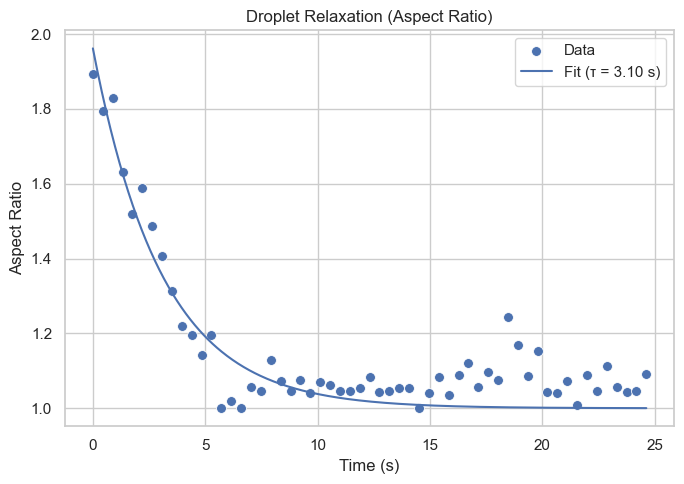

In [72]:
# =========================
# CELL 5: PLOTTING (AR)
# =========================

tfit = np.linspace(df["Time"].min(), df["Time"].max(), 500)

ar_fit = exp_AR(tfit, *popt_AR)

plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="Time",
    y="AR",
    s=50,
    label="Data"
)

sns.lineplot(
    x=tfit,
    y=ar_fit,
    label=f"Fit (τ = {tau_AR:.2f} s)"
)

plt.title("Droplet Relaxation (Aspect Ratio)")
plt.xlabel("Time (s)")
plt.ylabel("Aspect Ratio")

plt.tight_layout()
plt.show()

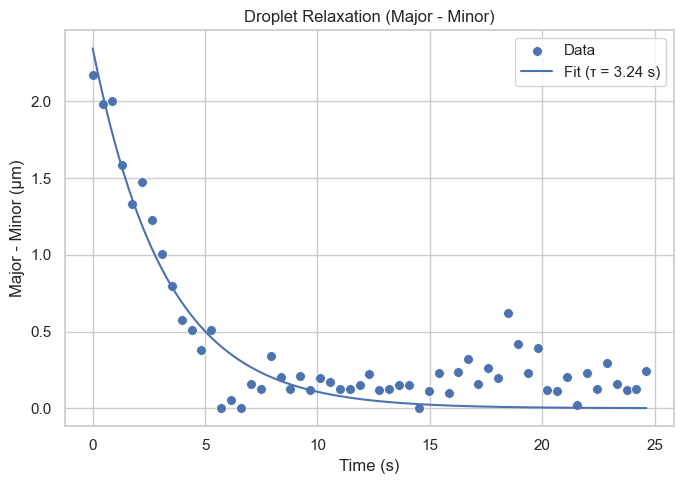

In [73]:
# =========================
# CELL 6: PLOTTING (D = Major - Minor)
# =========================

d_fit = exp_D(tfit, *popt_D)

plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="Time",
    y="D",
    s=50,
    label="Data"
)

sns.lineplot(
    x=tfit,
    y=d_fit,
    label=f"Fit (τ = {tau_D:.2f} s)"
)

plt.title("Droplet Relaxation (Major - Minor)")
plt.xlabel("Time (s)")
plt.ylabel("Major - Minor (µm)")

plt.tight_layout()
plt.show()

In [52]:
# =========================
# Radius and eta/gamma
# =========================

# Calculate equivalent radius (µm)
df["Radius_um"] = np.sqrt(df["Area"] / np.pi)

# Convert to metres
df["Radius_m"] = df["Radius_um"] * 1e-6

# Use the mean radius of the last 5 frames
R_mean = df["Radius_m"].tail(5).mean()

print(f"Mean equivalent radius = {R_mean*1e6:.2f} µm")

# Calculate viscosity/interfacial tension ratio
eta_over_gamma_AR = tau_AR / R_mean

print(f"η/γ = {eta_over_gamma_AR:.3e} s/m")

# If you prefer using the D fit instead:
eta_over_gamma_D = tau_D / R_mean

print(f"η/γ (from D fit) = {eta_over_gamma_D:.3e} s/m")

Mean equivalent radius = 0.89 µm
η/γ = 3.526e+06 s/m
η/γ (from D fit) = 3.866e+06 s/m


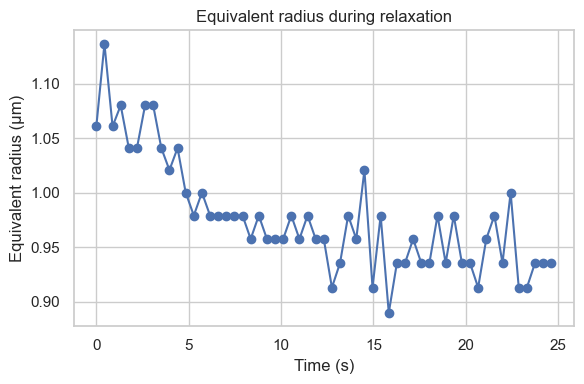

In [46]:
plt.figure(figsize=(6,4))
plt.plot(df["Time"], df["Radius_um"], "o-")
plt.xlabel("Time (s)")
plt.ylabel("Equivalent radius (µm)")
plt.title("Equivalent radius during relaxation")
plt.tight_layout()
plt.show()

In [75]:

# =========================
# OUTPUT SUMMARY
# =========================

summary_file = "/Users/parth/dev/boekhoven_lab/data/droplet_fusion/PEG10K_5wt%_fusion_summary_2.csv"

# Name of the analysed CSV/movie
sample_name = os.path.basename(csv_file)

# Prepare one row of results
summary = pd.DataFrame({
    "Sample": [sample_name],
    "Tau_AR_s": [tau_AR],
    "Tau_D_s": [tau_D],
    "Radius_um": [R_mean * 1e6],
    "Radius_m": [R_mean],
    "Eta_over_Gamma_AR_s_per_m": [eta_over_gamma_AR],
    "Eta_over_Gamma_D_s_per_m": [eta_over_gamma_D]
})

# Append or create file
if os.path.exists(summary_file):
    summary.to_csv(summary_file, mode="a", header=False, index=False)
else:
    summary.to_csv(summary_file, index=False)

print(f"Results appended to '{summary_file}'")
print(summary)

Results appended to '/Users/parth/dev/boekhoven_lab/data/droplet_fusion/PEG10K_5wt%_fusion_summary_2.csv'
             Sample  Tau_AR_s   Tau_D_s  Radius_um      Radius_m  \
0  PKU_039_5%_7.csv  3.098329  3.243041   0.894128  8.941282e-07   

   Eta_over_Gamma_AR_s_per_m  Eta_over_Gamma_D_s_per_m  
0               3.526427e+06              3.866291e+06  


Control
  τ = 2.558 s
  R = 1.78 µm
  η/γ = 1.439e+06 s/m

PEG10K 5 wt%
  τ = 4.781 s
  R = 1.14 µm
  η/γ = 4.180e+06 s/m

PEG10K 10 wt%
  τ = 6.729 s
  R = 1.30 µm
  η/γ = 5.192e+06 s/m


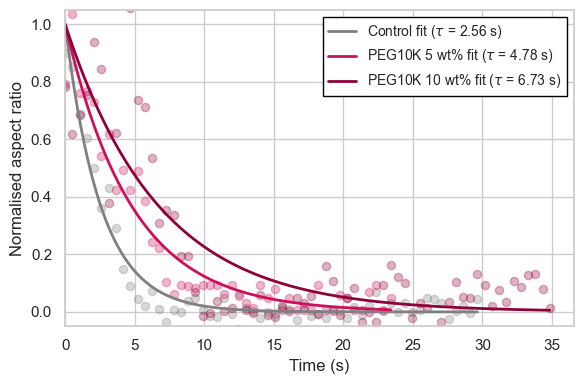

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ============================================
# USER INPUT
# ============================================

csv_control = "/Users/parth/dev/boekhoven_lab/data/droplet_fusion/PKU_038_Control_4.csv"
csv_peg_5 = "/Users/parth/dev/boekhoven_lab/data/droplet_fusion/PKU_039_5%_3.csv"
csv_peg_10 = "/Users/parth/dev/boekhoven_lab/data/droplet_fusion/PKU_051_10%_3.csv"

dt = 0.52  # seconds per frame

control_colour = "#808080"
peg_5_colour = "#226E9C"
peg_10_colour = "#0D4A70"

# ============================================
# Exponential model
# ============================================

def exp_decay(t, AR_inf, A0, tau):
    return AR_inf + A0 * np.exp(-t / tau)

# ============================================
# Analyse one dataset
# ============================================

def analyse(csv_file):

    df = pd.read_csv(csv_file)

    # Time axis
    df["Time"] = np.arange(len(df)) * dt

    # Aspect ratio
    df["AR"] = df["Major"] / df["Minor"]

    # Radius
    df["Radius_um"] = np.sqrt(df["Area"] / np.pi)
    df["Radius_m"] = df["Radius_um"] * 1e-6
    R_mean = df["Radius_m"].tail(5).mean()

    # ---- Fit AR ----

    p0 = [
        1.0,
        df["AR"].iloc[0] - 1.0,
        5.0
    ]

    popt, _ = curve_fit(
        exp_decay,
        df["Time"],
        df["AR"],
        p0=p0,
        maxfev=10000
    )

    AR_inf, A0, tau = popt

    # η/γ
    eta_over_gamma = tau / R_mean

    # Normalised AR
    df["AR_norm"] = (df["AR"] - AR_inf) / A0

    return df, tau, R_mean, eta_over_gamma, popt

# ============================================
# Analyse both datasets
# ============================================

control_df, tau_control, R_control, eta_gamma_control, fit_control = analyse(csv_control)
peg_5_df, tau_peg_5, R_peg_5, eta_gamma_peg_5, fit_peg_5 = analyse(csv_peg_5)
peg_10_df, tau_peg_10, R_peg_10, eta_gamma_peg_10, fit_peg_10 = analyse(csv_peg_10)

print("Control")
print(f"  τ = {tau_control:.3f} s")
print(f"  R = {R_control*1e6:.2f} µm")
print(f"  η/γ = {eta_gamma_control:.3e} s/m")

print()

print("PEG10K 5 wt%")
print(f"  τ = {tau_peg_5:.3f} s")
print(f"  R = {R_peg_5*1e6:.2f} µm")
print(f"  η/γ = {eta_gamma_peg_5:.3e} s/m")

print()

print("PEG10K 10 wt%")
print(f"  τ = {tau_peg_10:.3f} s")
print(f"  R = {R_peg_10*1e6:.2f} µm")
print(f"  η/γ = {eta_gamma_peg_10:.3e} s/m")

# ============================================
# Plot
# ============================================

plt.figure(figsize=(6,4))

# Control data
plt.scatter(
    control_df["Time"],
    control_df["AR_norm"],
    color=control_colour,
    s=35,
    alpha=0.3,
    # label="Control"
)

tfit = np.linspace(
    control_df["Time"].min(),
    control_df["Time"].max(),
    400
)

AR_inf, A0, tau = fit_control
fit_norm = (exp_decay(tfit, *fit_control) - AR_inf) / A0

plt.plot(
    tfit,
    fit_norm,
    color=control_colour,
    lw=2,
    label=fr"Control fit ($\tau$ = {tau_control:.2f} s)"
)

# PEG 5wt% data
plt.scatter(
    peg_5_df["Time"],
    peg_5_df["AR_norm"],
    color=peg_5_colour,
    s=35,
    alpha=0.3,
    # label="PEG10K 5 wt%"
)

tfit = np.linspace(
    peg_5_df["Time"].min(),
    peg_5_df["Time"].max(),
    400
)

AR_inf, A0, tau = fit_peg_5
fit_norm = (exp_decay(tfit, *fit_peg_5) - AR_inf) / A0

plt.plot(
    tfit,
    fit_norm,
    color=peg_5_colour,
    lw=2,
    label=fr"PEG10K 5 wt% fit ($\tau$ = {tau_peg_5:.2f} s)"
)

# PEG 10wt% data
plt.scatter(
    peg_10_df["Time"],
    peg_10_df["AR_norm"],
    color=peg_10_colour,
    s=35,
    alpha=0.3,
    # label="PEG10K 10 wt%"
)

tfit = np.linspace(
    peg_10_df["Time"].min(),
    peg_10_df["Time"].max(),
    400
)

AR_inf, A0, tau = fit_peg_10
fit_norm = (exp_decay(tfit, *fit_peg_10) - AR_inf) / A0

plt.plot(
    tfit,
    fit_norm,
    color=peg_10_colour,
    lw=2,
    label=fr"PEG10K 10 wt% fit ($\tau$ = {tau_peg_10:.2f} s)"
)

plt.xlabel("Time (s)", fontsize=12)
plt.ylabel("Normalised aspect ratio", fontsize=12)

plt.xlim(left=0)
plt.ylim(-0.05, 1.05)

plt.legend(
    frameon=True,
    fancybox=False,
    edgecolor="black",
    framealpha=1,
    fontsize=10
)

plt.tight_layout()
plt.show()